# Clustering

Arya Bima Nugraha (238)

M. Haekal Fallah Ar-Rahman (061)


## 1. Import library

In [ ]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn import metrics
from scipy.cluster.hierarchy import linkage, dendrogram

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)

## 2. Load data hasil preprocessing (Exercise 4) dan hitung fitur

In [ ]:
df = pd.read_csv('exercise4_text_preprocessed_excel.csv', sep=';', encoding='utf-8-sig')
df = df.dropna(subset=['prepro']).reset_index(drop=True)
df_pre = df['prepro']

video_id = df['video_id'].tolist()
doc = [f'D{i+1}' for i in range(len(df))]
df.insert(0, 'doc', doc)

FE, M = {}, {}
for name, vec in [('OHE', CountVectorizer(binary=True)), ('BoW', CountVectorizer()), ('TF-IDF', TfidfVectorizer())]:
    X_ = vec.fit_transform(df_pre)
    FE[name] = pd.DataFrame(X_.toarray(), columns=vec.get_feature_names_out())
    M[name] = FE[name].values

if os.path.exists('exercise5_feature_engineering.xlsx'):
    for name, sh in [('Word2Vec', 'Word2Vec (vektor dokumen)'), ('FastText', 'FastText (vektor dokumen)')]:
        FE[name] = pd.read_excel('exercise5_feature_engineering.xlsx', sheet_name=sh).drop(columns='video_id')
        M[name] = FE[name].values.astype(float)

for k, v in M.items():
    print(f'{k:9s} shape = {v.shape}')
df[['doc', 'video_id', 'prepro']]

OHE       shape = (8, 65)
BoW       shape = (8, 65)
TF-IDF    shape = (8, 65)
Word2Vec  shape = (8, 100)
FastText  shape = (8, 100)


  doc     video_id                                                                                        prepro
0  D1  SrvLb03AXok  first love letter 1991 movi detail direct renown filmmak romant drama follow heartfelt stori
1  D2  bDe5W2I8Sgc                            journalist anonym confess secret feel love letter sent best friend
2  D3  ffuFHYh6TWs                                                  data de lançamento 25 de março de 1995 japão
3  D4  WsKyc8gJW1k                                      anoth rare time travel movi sort avail anywher els onlin
4  D5  P6JAtpSC0EA                                             direct shunji iwai miho nakayama etsushi toyokawa
5  D6  sV9JaCWTDgE                             first love letter 1991 superhit hindi romant movi full drama emot
6  D7  V_tCZB4YRbE                              director shunji iwai writer shunji iwai star icon mountain scene
7  D8  tvneMVSrvbU                           theater june 5 hiroko still depth grief year fiancé

In [ ]:
def evaluate(X, labels):
    """Metrik internal clustering (slide Metrics of Clustering)."""
    return {
        'Silhouette (↑)'       : round(metrics.silhouette_score(X, labels), 3),
        'Davies-Bouldin (↓)'   : round(metrics.davies_bouldin_score(X, labels), 3),
        'Calinski-Harabasz (↑)': round(metrics.calinski_harabasz_score(X, labels), 3),
    }

def members(labels):
    """Anggota tiap cluster."""
    out = {}
    for c in sorted(set(labels)):
        out[f'Cluster {c}'] = [doc[i] for i in range(len(labels)) if labels[i] == c]
    return out

## 3. K-Means

### 3.1 Menentukan k (elbow + silhouette) pada TF-IDF

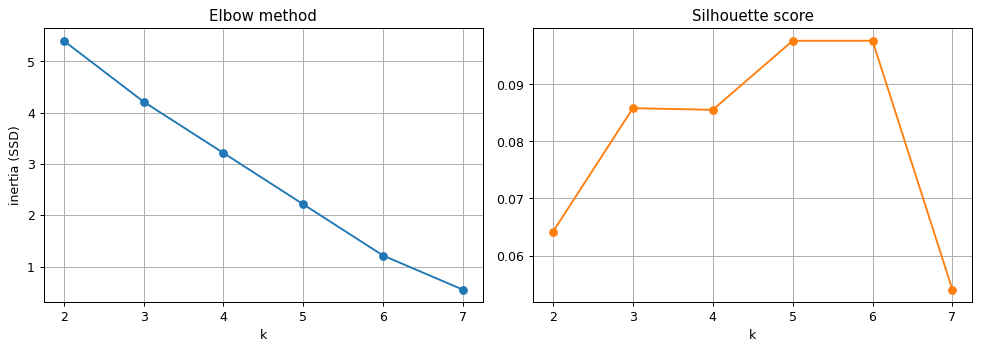

   k  inertia  silhouette
0  2    5.404       0.064
1  3    4.214       0.086
2  4    3.214       0.086
3  5    2.212       0.098
4  6    1.212       0.098
5  7    0.546       0.054

In [ ]:
X = M['TF-IDF']
ks = range(2, 8)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=10, n_init=100).fit(X)
    inertia.append(km.inertia_)
    sil.append(metrics.silhouette_score(X, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(list(ks), inertia, marker='o'); ax[0].set_title('Elbow method'); ax[0].set_xlabel('k'); ax[0].set_ylabel('inertia (SSD)'); ax[0].grid()
ax[1].plot(list(ks), sil, marker='o', color='tab:orange'); ax[1].set_title('Silhouette score'); ax[1].set_xlabel('k'); ax[1].grid()
plt.tight_layout(); plt.show()
pd.DataFrame({'k': list(ks), 'inertia': np.round(inertia, 3), 'silhouette': np.round(sil, 3)})

**Analisis:** inertia turun hampir lurus dari k=2 sampai k=7, sehingga tidak ada "siku" yang jelas. Ini wajar karena hanya ada 8 dokumen yang topiknya beragam. Silhouette juga rendah di semua k (maksimum sekitar 0.098 pada k=5 dan 6), artinya struktur cluster pada data ini lemah. Kami memakai **k = 3** karena hasilnya masih bisa ditafsirkan (tidak banyak cluster berisi satu dokumen) dan silhouette-nya sama dengan k=4 (0.086).

Catatan teknis: `n_init=100` dipakai agar K-Means tidak terjebak di optimum lokal. Dengan `n_init=10`, pada k=3 hasilnya kadang berbeda (inertia 4.272 vs 4.214) karena inisialisasi centroid acak.

### 3.2 K-Means dengan k = 3 (TF-IDF)

In [ ]:
n_clusters = 3

kM = KMeans(n_clusters=n_clusters, random_state=10, n_init=100).fit(X)
df['Kmeans_label'] = kM.labels_
print('Silhouette  :', round(metrics.silhouette_score(X, kM.labels_), 3))
print('Davies-Bouldin:', round(metrics.davies_bouldin_score(X, kM.labels_), 3))
print('Calinski-Harabasz:', round(metrics.calinski_harabasz_score(X, kM.labels_), 3))
print(members(kM.labels_))
df[['doc', 'video_id', 'Kmeans_label', 'prepro']]

Silhouette  : 0.086
Davies-Bouldin: 1.611
Calinski-Harabasz: 1.474
{'Cluster 0': ['D1', 'D2', 'D6'], 'Cluster 1': ['D5', 'D7'], 'Cluster 2': ['D3', 'D4', 'D8']}


  doc     video_id  Kmeans_label                                                                                        prepro
0  D1  SrvLb03AXok             0  first love letter 1991 movi detail direct renown filmmak romant drama follow heartfelt stori
1  D2  bDe5W2I8Sgc             0                            journalist anonym confess secret feel love letter sent best friend
2  D3  ffuFHYh6TWs             2                                                  data de lançamento 25 de março de 1995 japão
3  D4  WsKyc8gJW1k             2                                      anoth rare time travel movi sort avail anywher els onlin
4  D5  P6JAtpSC0EA             1                                             direct shunji iwai miho nakayama etsushi toyokawa
5  D6  sV9JaCWTDgE             0                             first love letter 1991 superhit hindi romant movi full drama emot
6  D7  V_tCZB4YRbE             1                              director shunji iwai writer shunji iwai star icon

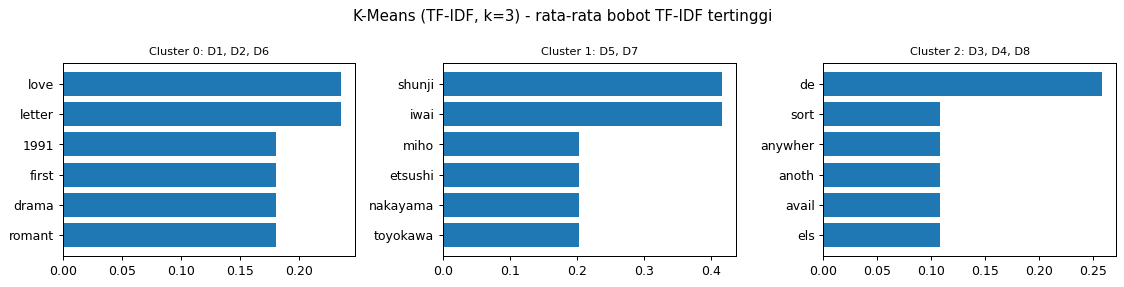

In [ ]:
def plot_top_terms(X, labels, feature_names, title, topn=6):
    cl = sorted(set(labels))
    fig, axes = plt.subplots(1, len(cl), figsize=(4.2 * len(cl), 3.2))
    for ax, c in zip(np.atleast_1d(axes), cl):
        idx = np.where(np.array(labels) == c)[0]
        mean = pd.Series(X[idx].mean(axis=0), index=feature_names).sort_values(ascending=False).head(topn)
        ax.barh(mean.index[::-1], mean.values[::-1], color='tab:blue')
        ax.set_title(f'Cluster {c}: ' + ', '.join(doc[i] for i in idx), fontsize=9)
    fig.suptitle(title); plt.tight_layout(); plt.show()

plot_top_terms(M['TF-IDF'], kM.labels_, FE['TF-IDF'].columns, 'K-Means (TF-IDF, k=3) - rata-rata bobot TF-IDF tertinggi')

**Analisis K-Means (TF-IDF, k=3):** terbentuk cluster {D1, D2, D6}, {D5, D7}, dan {D3, D4, D8}. Cluster {D5, D7} jelas: keduanya berisi kredit sutradara/penulis (kata *iwai*, *shunji*, *direct*). Cluster {D1, D2, D6} adalah kelompok surat cinta dan film romantis: ketiganya berbagi kata *letter* dan *love*, dan D1 dengan D6 juga berbagi *1991, drama, first, romant*. Cluster {D3, D4, D8} bukan kelompok yang bermakna: dokumennya hampir tidak berbagi kata satu sama lain (data rilis berbahasa Portugis, film langka yang tersedia online, dan kisah duka), jadi hanya menjadi "sisa". Silhouette 0.086 dan Davies-Bouldin 1.611 menunjukkan cluster saling berdekatan.

## 4. Hierarchical Clustering

### 4.1 Dendrogram (TF-IDF)

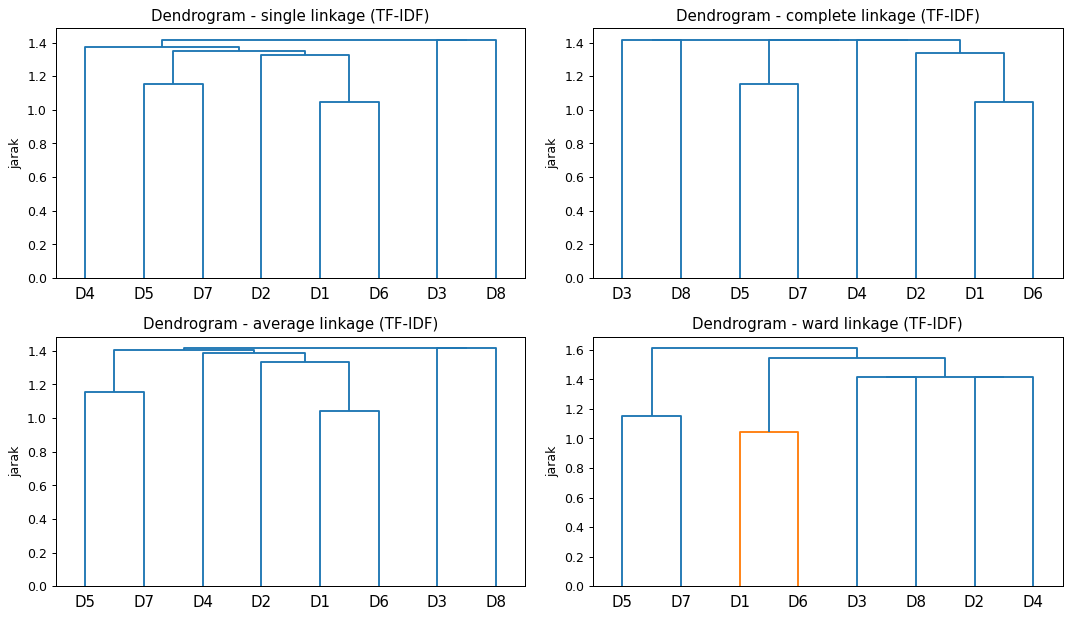

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, m in zip(axes.ravel(), ['single', 'complete', 'average', 'ward']):
    Z = linkage(M['TF-IDF'], method=m, metric='euclidean')
    dendrogram(Z, labels=doc, ax=ax)
    ax.set_title(f'Dendrogram - {m} linkage (TF-IDF)'); ax.set_ylabel('jarak')
plt.tight_layout(); plt.show()

**Analisis dendrogram:** *single* dan *average linkage* menghasilkan efek rantai: D3 dan D8 bergabung paling akhir sebagai dokumen tunggal, sisanya menumpuk dalam satu cluster besar. Pada k=3 hasilnya {6, 1, 1} dokumen, yang kurang berguna. *Complete* dan *ward* menghasilkan cluster yang lebih seimbang.

### 4.2 Agglomerative clustering (k = 3) untuk tiap linkage

In [ ]:
rows = []
for m in ['single', 'complete', 'average', 'ward']:
    lab = AgglomerativeClustering(n_clusters=n_clusters, linkage=m).fit_predict(M['TF-IDF'])
    df[f'{m}_label'] = lab
    rows.append({'Linkage': m, **evaluate(M['TF-IDF'], lab), 'Anggota': members(lab)})
pd.DataFrame(rows).set_index('Linkage')

          Silhouette (↑)  Davies-Bouldin (↓)  Calinski-Harabasz (↑)                                                                                        Anggota
Linkage                                                                                                                                                           
single             0.033               0.787                  1.142  {'Cluster 0': ['D1', 'D2', 'D4', 'D5', 'D6', 'D7'], 'Cluster 1': ['D8'], 'Cluster 2': ['D3']}
complete           0.078               1.555                  1.420  {'Cluster 0': ['D1', 'D2', 'D4', 'D6'], 'Cluster 1': ['D3', 'D8'], 'Cluster 2': ['D5', 'D7']}
average            0.033               0.787                  1.142  {'Cluster 0': ['D1', 'D2', 'D4', 'D5', 'D6', 'D7'], 'Cluster 1': ['D8'], 'Cluster 2': ['D3']}
ward               0.094               1.494                  1.476  {'Cluster 0': ['D2', 'D3', 'D4', 'D8'], 'Cluster 1': ['D5', 'D7'], 'Cluster 2': ['D1', 'D6']}

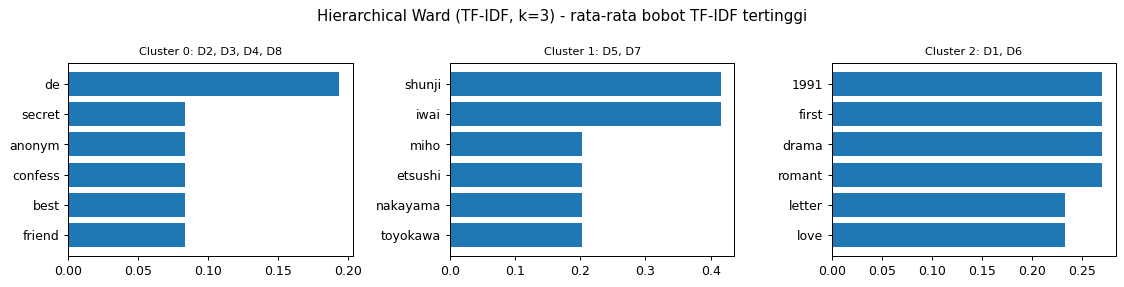

In [ ]:
plot_top_terms(M['TF-IDF'], df['ward_label'].values, FE['TF-IDF'].columns, 'Hierarchical Ward (TF-IDF, k=3) - rata-rata bobot TF-IDF tertinggi')

**Analisis:** *Ward linkage* punya silhouette tertinggi di antara keempat linkage (0.094) dan satu-satunya yang memisahkan {D1, D6} sebagai cluster tersendiri. *Complete linkage* (0.078) membentuk {D1, D2, D4, D6}, {D3, D8}, {D5, D7}. Nilai Davies-Bouldin *single* dan *average* terlihat paling bagus (0.787), tetapi itu menyesatkan: cluster berisi satu dokumen punya compactness 0, sehingga DBI menjadi kecil padahal pembagiannya tidak informatif.

Perbedaan K-Means dan Ward ada pada D2 (surat cinta anonim): K-Means menggabungkannya dengan {D1, D6} karena berbagi *letter* dan *love*, sedangkan Ward membiarkannya di cluster sisa.

Hasil *ward* paling mudah ditafsirkan:
- {D1, D6}: film drama romantis 1991, *first love letter* (kata *1991, drama, first, letter, love, romant*).
- {D5, D7}: informasi sutradara Shunji Iwai.
- {D2, D3, D4, D8}: cluster sisa tanpa tema bersama (surat cinta anonim, data rilis berbahasa Portugis, film langka online, kisah duka).

## 5. Semua metode x semua fitur (k = 3)

Setiap representasi fitur dari Exercise 5 dicoba dengan K-Means dan keempat linkage.

In [ ]:
methods = {
    'K-Means'         : lambda X: KMeans(n_clusters=3, random_state=10, n_init=100).fit_predict(X),
    'Single linkage'  : lambda X: AgglomerativeClustering(n_clusters=3, linkage='single').fit_predict(X),
    'Complete linkage': lambda X: AgglomerativeClustering(n_clusters=3, linkage='complete').fit_predict(X),
    'Average linkage' : lambda X: AgglomerativeClustering(n_clusters=3, linkage='average').fit_predict(X),
    'Ward linkage'    : lambda X: AgglomerativeClustering(n_clusters=3, linkage='ward').fit_predict(X),
}
res, all_labels = [], {}
for fe, Xf in M.items():
    for mn, f in methods.items():
        lab = f(Xf)
        all_labels[(fe, mn)] = lab
        res.append({'Fitur': fe, 'Metode': mn, **evaluate(Xf, lab), 'Ukuran cluster': sorted(np.bincount(lab), reverse=True)})
res = pd.DataFrame(res)
res

       Fitur            Metode  Silhouette (↑)  Davies-Bouldin (↓)  Calinski-Harabasz (↑) Ukuran cluster
0        OHE           K-Means           0.104               1.117                  1.694      [5, 2, 1]
1        OHE    Single linkage           0.036               0.764                  1.250      [6, 1, 1]
2        OHE  Complete linkage           0.104               1.117                  1.694      [5, 2, 1]
3        OHE   Average linkage           0.104               1.117                  1.694      [5, 2, 1]
4        OHE      Ward linkage           0.104               1.117                  1.694      [5, 2, 1]
5        BoW           K-Means           0.078               1.323                  1.676      [4, 3, 1]
6        BoW    Single linkage           0.045               0.734                  1.378      [6, 1, 1]
7        BoW  Complete linkage           0.078               1.174                  1.621      [5, 2, 1]
8        BoW   Average linkage           0.045         

In [ ]:
res.pivot(index='Fitur', columns='Metode', values='Silhouette (↑)')[list(methods)]

Metode    K-Means  Single linkage  Complete linkage  Average linkage  Ward linkage
Fitur                                                                             
BoW         0.078           0.045             0.078            0.045         0.092
FastText    0.351           0.351             0.351            0.351         0.351
OHE         0.104           0.036             0.104            0.104         0.104
TF-IDF      0.086           0.033             0.078            0.033         0.094
Word2Vec    0.130           0.053             0.140            0.140         0.130

**Analisis:**
- Pada fitur sparse (OHE, BoW, TF-IDF), skor paling tinggi hanya 0.104 (OHE). Semua nilai silhouette di bawah 0.15, jadi tidak ada konfigurasi yang menghasilkan cluster tegas.
- **FastText** mendapat skor tertinggi (silhouette 0.351, DBI 0.344, CH 5.669) dan semua metode menghasilkan partisi yang sama: D3 sendiri, D8 sendiri, enam dokumen lain satu cluster. Skor tinggi ini berasal dari terpisahnya dua dokumen *outlier*, bukan dari tema yang terkelompok. Selain itu embedding dilatih hanya dari 8 dokumen (nilai vektor sekitar 0.001 sampai 0.01), jadi sebaiknya tidak dianggap lebih "benar" daripada TF-IDF.
- **Word2Vec** (CBOW) sedikit lebih baik daripada fitur sparse (0.13 sampai 0.14), dengan pembagian yang mirip OHE/BoW.
- **Single dan average linkage** selalu rendah silhouette-nya dan cenderung membentuk cluster 6-1-1 karena efek rantai.

In [ ]:
rows = []
for fe, Xf in M.items():
    for mn, mk in {'K-Means': lambda X, k: KMeans(n_clusters=k, random_state=10, n_init=100).fit_predict(X),
                   'Ward': lambda X, k: AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X)}.items():
        s = {k: round(metrics.silhouette_score(Xf, mk(Xf, k)), 3) for k in range(2, 6)}
        best = max(s, key=s.get)
        rows.append({'Fitur': fe, 'Metode': mn, 'Silhouette k=2..5': s, 'k terbaik': best})
pd.DataFrame(rows)

      Fitur   Metode                         Silhouette k=2..5  k terbaik
0       OHE  K-Means  {2: 0.119, 3: 0.104, 4: 0.097, 5: 0.103}          2
1       OHE     Ward  {2: 0.119, 3: 0.104, 4: 0.096, 5: 0.103}          2
2       BoW  K-Means  {2: 0.086, 3: 0.078, 4: 0.112, 5: 0.107}          4
3       BoW     Ward  {2: 0.086, 3: 0.092, 4: 0.112, 5: 0.107}          4
4    TF-IDF  K-Means  {2: 0.064, 3: 0.086, 4: 0.086, 5: 0.098}          5
5    TF-IDF     Ward   {2: 0.064, 3: 0.094, 4: 0.09, 5: 0.098}          5
6  Word2Vec  K-Means   {2: 0.132, 3: 0.13, 4: 0.162, 5: 0.136}          4
7  Word2Vec     Ward   {2: 0.106, 3: 0.13, 4: 0.162, 5: 0.136}          4
8  FastText  K-Means    {2: 0.26, 3: 0.351, 4: 0.166, 5: 0.09}          3
9  FastText     Ward   {2: 0.343, 3: 0.351, 4: 0.166, 5: 0.09}          3

**Analisis:** k terbaik berbeda-beda (k=2 untuk OHE, k=3 untuk FastText, k=4 untuk BoW dan Word2Vec, k=5 untuk TF-IDF), dan selisih skornya kecil. Ini menguatkan bahwa jumlah cluster alami pada 8 dokumen ini tidak jelas.

## 6. Kesepakatan antar metode (ARI, TF-IDF, k = 3)

In [ ]:
names = list(methods)
ari = pd.DataFrame(index=names, columns=names, dtype=float)
for a in names:
    for b in names:
        ari.loc[a, b] = metrics.adjusted_rand_score(all_labels[('TF-IDF', a)], all_labels[('TF-IDF', b)])
ari.round(2)

                  K-Means  Single linkage  Complete linkage  Average linkage  Ward linkage
K-Means              1.00            0.03              0.55             0.03          0.55
Single linkage       0.03            1.00              0.38             1.00         -0.18
Complete linkage     0.55            0.38              1.00             0.38          0.30
Average linkage      0.03            1.00              0.38             1.00         -0.18
Ward linkage         0.55           -0.18              0.30            -0.18          1.00

**Analisis:** single dan average linkage identik (ARI = 1.00). K-Means cukup sejalan dengan Ward dan complete linkage (ARI 0.55 untuk keduanya), tetapi hampir tidak sejalan dengan single/average (ARI 0.03). Ward bahkan negatif terhadap single/average. Jadi pilihan metode memang memengaruhi hasil pada data sekecil ini.

## 7. Menyimpan hasil ke Excel

In [ ]:
label_df = pd.DataFrame({'doc': doc, 'video_id': video_id})
for (fe, mn), lab in all_labels.items():
    label_df[f'{fe} | {mn}'] = lab

with pd.ExcelWriter('exercise7_clustering.xlsx', engine='openpyxl') as w:
    res.assign(**{'Ukuran cluster': res['Ukuran cluster'].astype(str)}).to_excel(w, sheet_name='Metrik', index=False)
    label_df.to_excel(w, sheet_name='Label cluster', index=False)
    df[['doc', 'video_id', 'prepro', 'Kmeans_label', 'single_label', 'complete_label', 'average_label', 'ward_label']].to_excel(w, sheet_name='TF-IDF k=3', index=False)
print('Tersimpan: exercise7_clustering.xlsx')

try:
    from google.colab import files
    files.download('exercise7_clustering.xlsx')
except ImportError:
    pass

Tersimpan: exercise7_clustering.xlsx


## 8. Kesimpulan

1. **Metode terbaik secara interpretasi** adalah *Ward linkage* pada TF-IDF (k=3). Metode ini memberi tiga cluster bermakna (film romantis 1991, kredit Shunji Iwai, dan cluster sisa), dengan silhouette tertinggi di antara keempat linkage pada TF-IDF (0.094).
2. **Metode terbaik secara angka** adalah fitur FastText (silhouette 0.351), tetapi hanya karena memisahkan dua dokumen outlier (D3 dan D8).
3. Semua skor internal rendah (kecuali FastText), yang menandakan dokumen-dokumen ini memang tidak membentuk kelompok topik yang tegas. Penyebab utamanya adalah korpus hanya 8 dokumen dan topiknya beragam.
4. Single dan average linkage kurang cocok untuk data ini karena efek rantai. K-Means, Ward, dan complete linkage cukup sejalan (ARI 0.55).
5. Untuk hasil yang lebih meyakinkan, perlu lebih banyak dokumen. Dengan data lebih banyak, elbow dan silhouette juga lebih bisa diandalkan.